# 🛒 Análise de comportamento de clientes em um e-commerce

Este notebook analisa **1.000 clientes** de uma loja virtual para responder a uma pergunta de negócio:

> **O que faz um cliente gastar mais?**

Foram analisadas quatro informações de cada cliente: **número de visitas**, **tempo no site**, **itens no carrinho** e **valor da compra**.

**Etapas:**
1. Geração dos dados
2. Análise descritiva
3. Quanto tempo os clientes ficam no site
4. Tempo no site × valor da compra
5. O caminho do dinheiro: visitas, tempo, itens e valor
6. Conclusões e recomendações (storytelling)

> ⚠️ **Os dados são simulados** com NumPy, seguindo regras definidas na seção 1. O objetivo é praticar o processo completo de uma análise: gerar, explorar, visualizar e comunicar os resultados.

In [1]:
# Bibliotecas
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Pastas onde os gráficos e os dados serão salvos
Path("imagens").mkdir(exist_ok=True)
Path("dados").mkdir(exist_ok=True)

# Paleta e estilo dos gráficos: cores discretas na "moldura", cor forte só nos dados
AZUL = "#2a78d6"        # cor principal dos dados
CINZA_BARRA = "#c8c6bd" # barras sem destaque
TINTA = "#0b0b0b"       # textos principais
TINTA_2 = "#52514e"     # textos secundários
EIXO = "#898781"        # eixos
GRADE = "#e1e0d9"       # linhas de grade

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": EIXO,
    "axes.labelcolor": TINTA_2,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": GRADE,
    "grid.linewidth": 0.8,
    "xtick.color": TINTA_2,
    "ytick.color": TINTA_2,
})


def br(valor, casas=1):
    # Formata número no padrão brasileiro: 1234.5 -> '1.234,5'
    return f"{valor:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

In [2]:
# Versões das bibliotecas usadas (para quem quiser reproduzir a análise)
%load_ext watermark
%watermark -a "Tiago Dumont" --python --iversions

Author: Tiago Dumont

Python implementation: CPython
Python version       : 3.13.17
IPython version      : 9.18.1

matplotlib: 3.11.2
numpy     : 2.5.4
pandas    : 3.1.0
seaborn   : 0.13.2



## 1. Geração dos dados

Cada cliente recebe quatro informações, geradas com distribuições estatísticas diferentes:

| Variável | Como foi gerada | Por quê |
|---|---|---|
| **Visitas** | Uniforme entre 1 e 50 (`randint`) | Qualquer quantidade de visitas é igualmente provável |
| **Tempo no site** | Normal com média 20 min e desvio 5 min (`normal`), **+ 0,5 min por visita** | Quem visita mais conhece o site e passa mais tempo nele |
| **Itens no carrinho** | Poisson com média = tempo ÷ 10 (`poisson`) | Conta itens (0, 1, 2…) e cresce com o tempo no site |
| **Valor da compra** | R$ 35 por item + um ruído aleatório (`normal`) | Preço médio por item com alguma variação |

A **semente** (`np.random.seed(42)`) garante que os números sejam sempre os mesmos a cada execução.

In [3]:
np.random.seed(42)
n_usuarios = 1000

# Visitas: de 1 a 50 (o randint não inclui o número final, por isso 51)
n_visitas = np.random.randint(1, 51, size=n_usuarios)

# Tempo no site: normal(20, 5) + 0,5 min por visita, nunca negativo
tempo_no_site = np.random.normal(20, 5, size=n_usuarios) + n_visitas * 0.5
tempo_no_site = np.round(np.maximum(tempo_no_site, 0), 2)

# Itens no carrinho: Poisson (nunca gera número negativo)
n_itens_carrinho = np.random.poisson(lam=tempo_no_site / 10, size=n_usuarios)

# Valor da compra: R$ 35 por item + ruído, nunca negativo; zero se o carrinho está vazio
valores_compra = n_itens_carrinho * 35 + np.random.normal(loc=0, scale=10, size=n_usuarios)
valores_compra = np.maximum(valores_compra, 0)
valores_compra[n_itens_carrinho == 0] = 0
valores_compra = np.round(valores_compra, 2)

df = pd.DataFrame({
    "visitas": n_visitas,
    "tempo_no_site": tempo_no_site,
    "itens_carrinho": n_itens_carrinho,
    "valor_compra": valores_compra,
})

# Salva os dados em CSV (padrão brasileiro), pronto para abrir no Excel ou no Power BI
df.to_csv("dados/usuarios_ecommerce.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")

df.head()

,visitas,tempo_no_site,itens_carrinho,valor_compra
0,39,36.41,6,208.00
1,29,28.21,2,64.07
2,15,33.44,1,0.00
3,43,41.29,5,192.55
4,8,24.87,2,70.00


## 2. Análise descritiva

Média, desvio padrão, mínimo e máximo de cada variável, calculados com as funções do NumPy.

In [4]:
variaveis = {
    "Visitas": n_visitas,
    "Tempo no site (min)": tempo_no_site,
    "Itens no carrinho": n_itens_carrinho,
    "Valor da compra (R$)": valores_compra,
}

estatisticas = {}
for nome, dados in variaveis.items():
    estatisticas[nome] = {
        "Média": np.mean(dados),
        "Mediana": np.median(dados),
        "Desvio padrão": np.std(dados, ddof=1),  # ddof=1: desvio padrão da amostra
        "Mínimo": np.min(dados),
        "Máximo": np.max(dados),
    }

tabela = pd.DataFrame(estatisticas).T.round(2)
tabela

,Média,Mediana,Desvio padrão,Mínimo,Máximo
Visitas,25.83,26.00,14.35,1.00,50.00
Tempo no site (min),33.32,32.92,8.93,7.08,59.34
Itens no carrinho,3.28,3.00,1.99,0.00,12.00
Valor da compra (R$),114.96,107.15,70.67,0.00,418.86


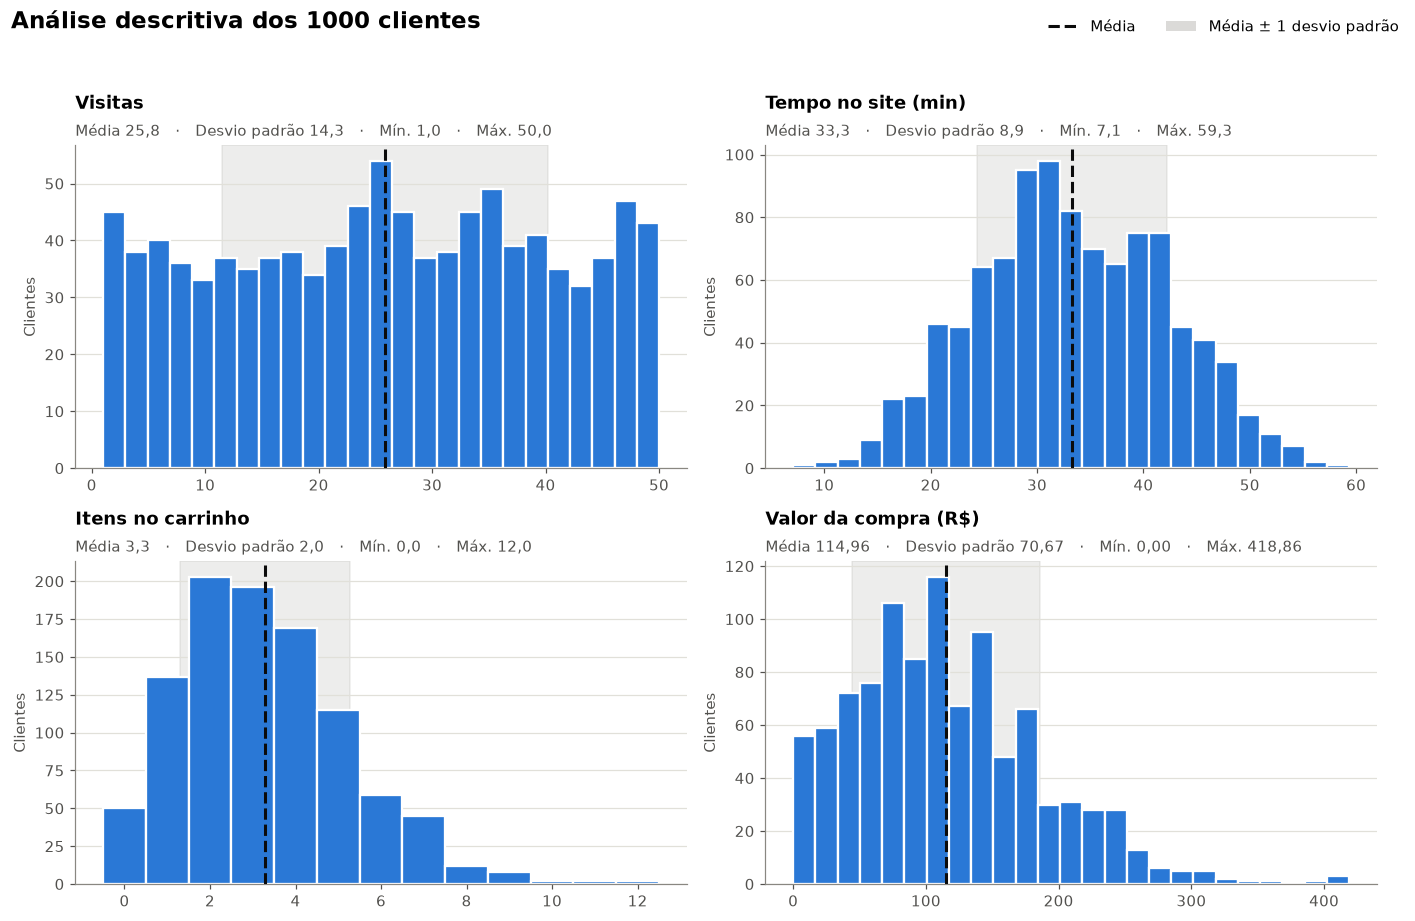

In [5]:
# As escalas são muito diferentes (itens: 0 a 12; valor: até R$ 400), então cada
# variável ganha o seu próprio gráfico, com a sua escala, na mesma figura.
fig, eixos = plt.subplots(2, 2, figsize=(13, 8.5))

for ax, (nome, dados) in zip(eixos.flat, variaveis.items()):
    est = estatisticas[nome]
    media, desvio = est["Média"], est["Desvio padrão"]

    ax.axvspan(media - desvio, media + desvio, color=EIXO, alpha=0.15, zorder=0)
    faixas = np.arange(dados.min() - 0.5, dados.max() + 1.5) if nome == "Itens no carrinho" else 25
    ax.hist(dados, bins=faixas, color=AZUL, edgecolor="white", linewidth=1.5, zorder=2)
    ax.axvline(media, color=TINTA, linewidth=2, linestyle="--", zorder=3)

    casas = 2 if "Valor" in nome else 1
    ax.set_title(nome, fontsize=12, pad=24)
    ax.text(0, 1.03,
            f"Média {br(media, casas)}   ·   Desvio padrão {br(desvio, casas)}   ·   "
            f"Mín. {br(est['Mínimo'], casas)}   ·   Máx. {br(est['Máximo'], casas)}",
            transform=ax.transAxes, fontsize=9.5, color=TINTA_2)
    ax.set_ylabel("Clientes")

fig.legend(
    handles=[
        Line2D([0], [0], color=TINTA, linewidth=2, linestyle="--", label="Média"),
        Patch(facecolor=EIXO, alpha=0.3, label="Média ± 1 desvio padrão"),
    ],
    loc="upper right", ncol=2, frameon=False, bbox_to_anchor=(0.99, 0.985),
)
fig.suptitle(f"Análise descritiva dos {n_usuarios} clientes", x=0.01, ha="left",
             fontsize=15, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig("imagens/01_analise_descritiva.png", dpi=120)
plt.show()

**O que a análise descritiva mostra:**

- **Visitas** têm distribuição **uniforme**: todas as faixas de 1 a 50 aparecem com frequência parecida.
- **Tempo no site** tem formato de **sino** (distribuição normal), concentrado entre 25 e 40 minutos.
- **Itens no carrinho:** a maioria dos clientes leva de 2 a 4 itens, e poucos passam de 8.
- **Valor da compra** tem uma **cauda à direita**: poucos clientes gastam mais de R$ 300, e eles puxam a média (R$ 114,96) para cima da mediana.

## 3. Quanto tempo os clientes ficam no site

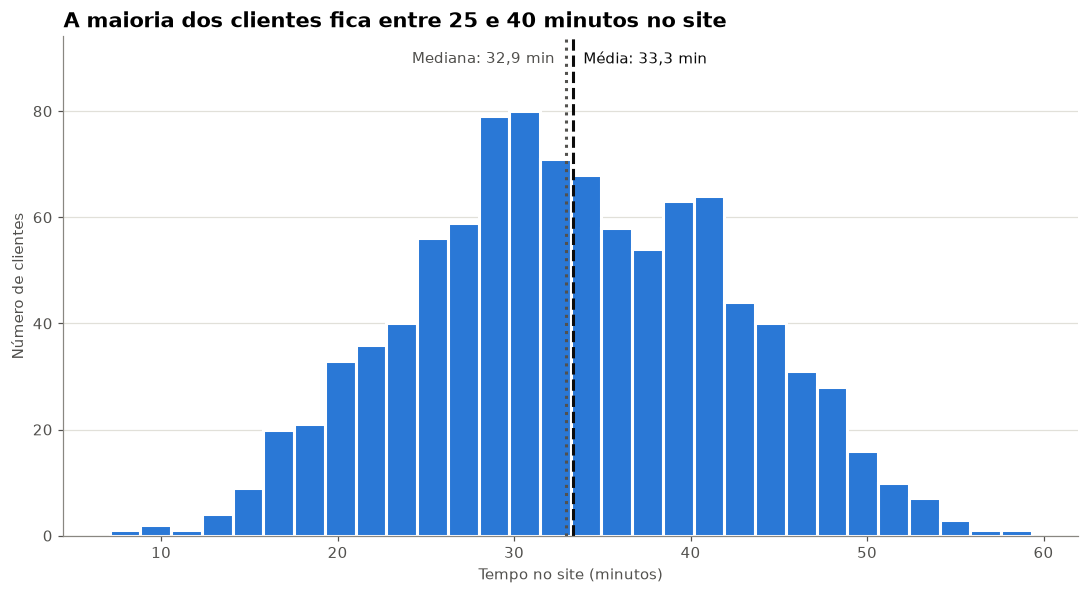

In [6]:
media = df["tempo_no_site"].mean()
mediana = df["tempo_no_site"].median()

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.hist(df["tempo_no_site"], bins=30, color=AZUL, edgecolor="white", linewidth=2)
ax.axvline(media, color=TINTA, linewidth=2, linestyle="--")
ax.axvline(mediana, color=TINTA_2, linewidth=2, linestyle=":")

topo = ax.get_ylim()[1] * 1.12
ax.set_ylim(0, topo)
fundo = {"facecolor": "white", "edgecolor": "none", "pad": 3}
ax.text(media + 0.6, topo * 0.97, f"Média: {br(media)} min", color=TINTA, va="top", bbox=fundo)
ax.text(mediana - 0.6, topo * 0.97, f"Mediana: {br(mediana)} min", color=TINTA_2,
        va="top", ha="right", bbox=fundo)

ax.set_title("A maioria dos clientes fica entre 25 e 40 minutos no site", fontsize=14)
ax.set_xlabel("Tempo no site (minutos)")
ax.set_ylabel("Número de clientes")
fig.tight_layout()
fig.savefig("imagens/02_tempo_no_site.png", dpi=120)
plt.show()

## 4. Tempo no site × valor da compra

Para comparar, os clientes foram divididos em **4 grupos do mesmo tamanho** (quartis), do mais rápido ao que mais fica no site.

In [7]:
df["faixa_tempo"] = pd.qcut(
    df["tempo_no_site"], q=4,
    labels=["Até 27 min", "27 a 33 min", "33 a 40 min", "Mais de 40 min"],
)

por_tempo = df.groupby("faixa_tempo", observed=True).agg(
    clientes=("valor_compra", "size"),
    gasto_medio=("valor_compra", "mean"),
    sem_compra=("itens_carrinho", lambda itens: (itens == 0).mean()),
    receita=("valor_compra", "sum"),
)
por_tempo["parte_da_receita"] = por_tempo["receita"] / por_tempo["receita"].sum()

por_tempo.style.format({
    "gasto_medio": "R$ {:.2f}", "sem_compra": "{:.0%}",
    "receita": "R$ {:,.2f}", "parte_da_receita": "{:.0%}",
})

,clientes,gasto_medio,sem_compra,receita,parte_da_receita
faixa_tempo,,,,,
Até 27 min,250,R$ 78.80,8%,"R$ 19,700.82",17%
27 a 33 min,250,R$ 106.00,6%,"R$ 26,499.49",23%
33 a 40 min,250,R$ 124.83,4%,"R$ 31,207.94",27%
Mais de 40 min,250,R$ 150.21,2%,"R$ 37,551.29",33%


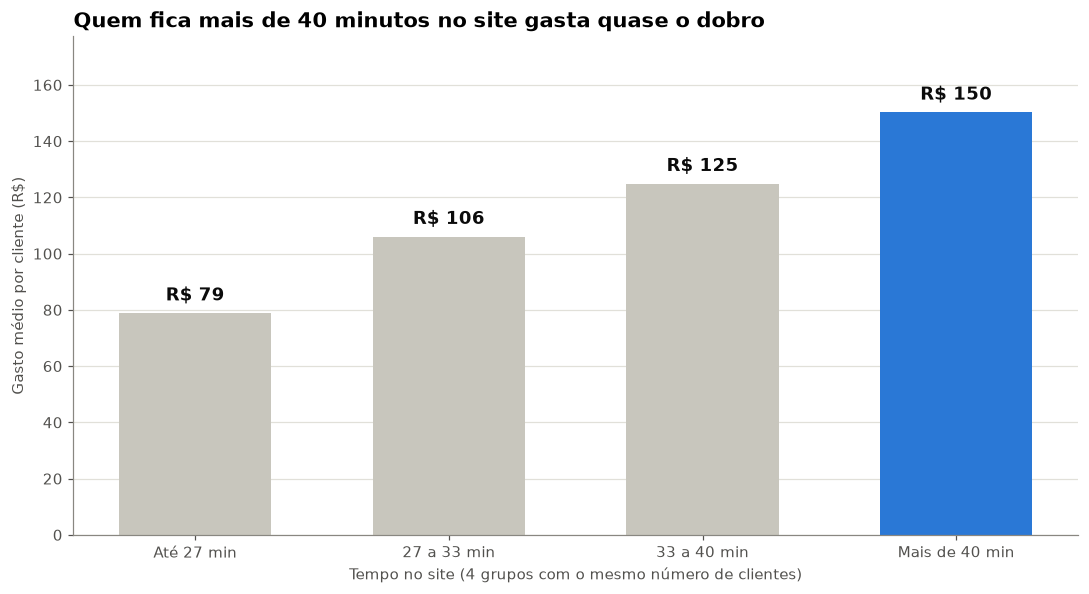

In [8]:
fig, ax = plt.subplots(figsize=(10, 5.5))

# Só o último grupo em azul: a cor aponta para onde o leitor deve olhar
cores = [CINZA_BARRA] * 3 + [AZUL]
barras = ax.bar(por_tempo.index.astype(str), por_tempo["gasto_medio"], color=cores, width=0.6)

for barra, valor in zip(barras, por_tempo["gasto_medio"]):
    ax.text(barra.get_x() + barra.get_width() / 2, valor + 3, f"R$ {br(valor, 0)}",
            ha="center", va="bottom", fontsize=12, fontweight="bold", color=TINTA)

ax.set_ylim(0, por_tempo["gasto_medio"].max() * 1.18)
ax.set_title("Quem fica mais de 40 minutos no site gasta quase o dobro", fontsize=14)
ax.set_xlabel("Tempo no site (4 grupos com o mesmo número de clientes)")
ax.set_ylabel("Gasto médio por cliente (R$)")
fig.tight_layout()
fig.savefig("imagens/03_gasto_por_tempo.png", dpi=120)
plt.show()

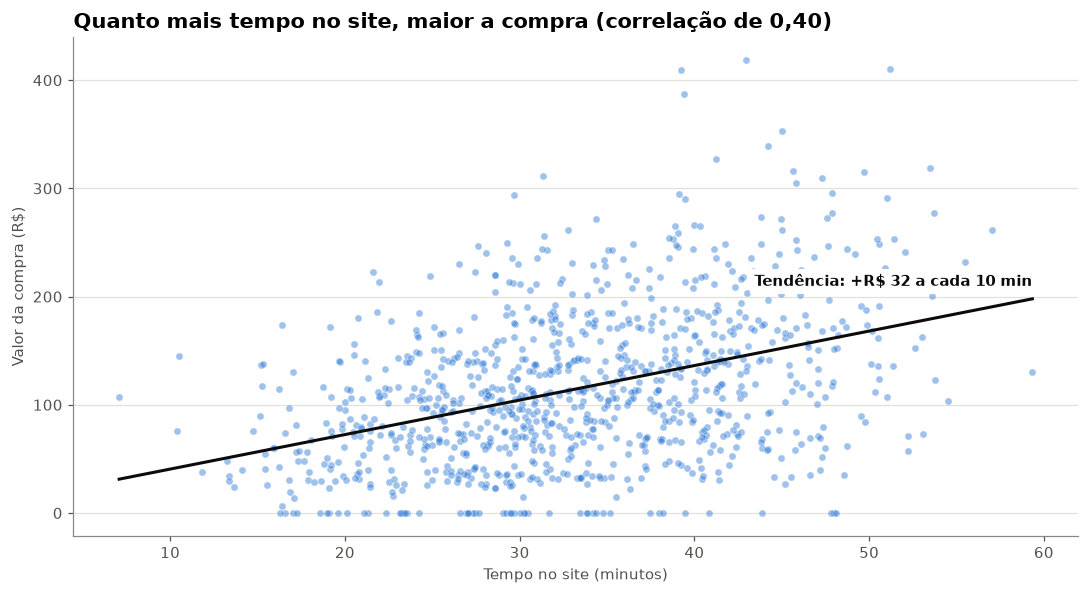

In [9]:
correlacao = df["tempo_no_site"].corr(df["valor_compra"])
inclinacao, intercepto = np.polyfit(df["tempo_no_site"], df["valor_compra"], deg=1)
x_linha = np.linspace(df["tempo_no_site"].min(), df["tempo_no_site"].max(), 100)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(df["tempo_no_site"], df["valor_compra"], s=22, color=AZUL, alpha=0.45,
           edgecolor="white", linewidth=0.5)
ax.plot(x_linha, inclinacao * x_linha + intercepto, color=TINTA, linewidth=2)
ax.text(x_linha[-1], inclinacao * x_linha[-1] + intercepto + 12,
        f"Tendência: +R$ {br(inclinacao * 10, 0)} a cada 10 min",
        ha="right", color=TINTA, fontsize=10, fontweight="bold",
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 3})

ax.set_title(f"Quanto mais tempo no site, maior a compra (correlação de {br(correlacao, 2)})",
             fontsize=14)
ax.set_xlabel("Tempo no site (minutos)")
ax.set_ylabel("Valor da compra (R$)")
fig.tight_layout()
fig.savefig("imagens/04_dispersao_tempo_valor.png", dpi=120)
plt.show()

## 5. O caminho do dinheiro

A **correlação** vai de -1 a 1 e mede o quanto duas variáveis andam juntas (perto de 1 = sobem juntas; perto de 0 = não têm relação).

In [10]:
df[["visitas", "tempo_no_site", "itens_carrinho", "valor_compra"]].corr().round(2)

,visitas,tempo_no_site,itens_carrinho,valor_compra
visitas,1.00,0.81,0.31,0.31
tempo_no_site,0.81,1.00,0.41,0.40
itens_carrinho,0.31,0.41,1.00,0.99
valor_compra,0.31,0.40,0.99,1.00


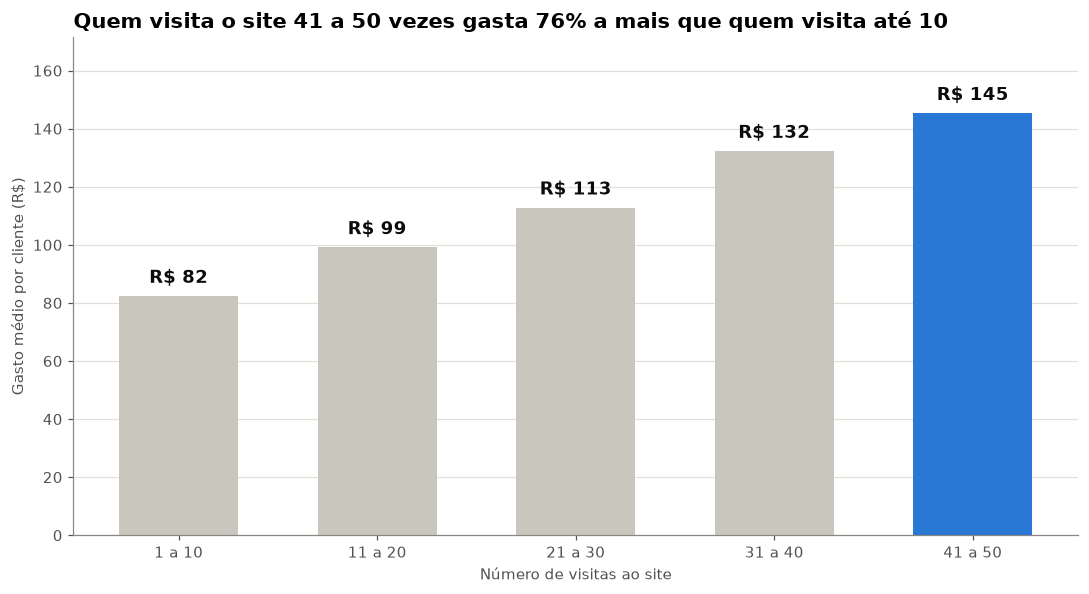

In [11]:
df["faixa_visitas"] = pd.cut(df["visitas"], bins=[0, 10, 20, 30, 40, 50],
                             labels=["1 a 10", "11 a 20", "21 a 30", "31 a 40", "41 a 50"])
por_visitas = df.groupby("faixa_visitas", observed=True)["valor_compra"].mean()

fig, ax = plt.subplots(figsize=(10, 5.5))
cores = [CINZA_BARRA] * 4 + [AZUL]
barras = ax.bar(por_visitas.index.astype(str), por_visitas.values, color=cores, width=0.6)
for barra, valor in zip(barras, por_visitas.values):
    ax.text(barra.get_x() + barra.get_width() / 2, valor + 3, f"R$ {br(valor, 0)}",
            ha="center", va="bottom", fontsize=12, fontweight="bold", color=TINTA)

ax.set_ylim(0, por_visitas.max() * 1.18)
aumento = por_visitas.iloc[-1] / por_visitas.iloc[0] - 1
ax.set_title(f"Quem visita o site 41 a 50 vezes gasta {aumento:.0%} a mais que quem visita até 10",
             fontsize=14)
ax.set_xlabel("Número de visitas ao site")
ax.set_ylabel("Gasto médio por cliente (R$)")
fig.tight_layout()
fig.savefig("imagens/05_gasto_por_visitas.png", dpi=120)
plt.show()

**O caminho do dinheiro:**

**Mais visitas → mais tempo no site → mais itens no carrinho → compra maior**

- Visitas e tempo no site andam muito juntos (correlação de **0,81**).
- O tempo no site puxa a quantidade de itens, e os itens definem o valor da compra (correlação de **0,99**).
- Quem visitou o site de 41 a 50 vezes gasta em média **R$ 145**; quem visitou até 10 vezes gasta **R$ 82**.

## 6. Conclusões e recomendações

### 🎯 A grande ideia
> **Quem fica mais tempo no site gasta quase o dobro. O desafio é fazer o cliente ficar e voltar.**

### Principais descobertas
1. **95% dos clientes compraram**, com ticket médio de **R$ 121** entre os compradores e faturamento total de **R$ 114.960**.
2. Os **25% que mais ficam no site** (mais de 40 min) gastam **R$ 150** em média, contra **R$ 79** dos 25% mais rápidos, e respondem por **33% da receita**.
3. Entre os mais rápidos, **8% saem sem comprar**; entre os que mais ficam, só **2%**.
4. Quem **volta mais vezes** ao site fica mais tempo e gasta mais.

### Recomendações
1. **Aumentar o tempo de navegação:** recomendações de produtos ("quem viu também viu"), conteúdo e comparadores.
2. **Trazer o cliente de volta:** e-mail, WhatsApp e remarketing para quem visitou poucas vezes.
3. **Medir o resultado com um teste A/B:** meta de subir o gasto médio do grupo mais rápido de R$ 79 para R$ 100.

### ⚠️ Limitações
- **Correlação não é causa.** Os dados mostram que quem fica mais tempo gasta mais, mas não provam que *fazer* o cliente ficar mais tempo vai aumentar o gasto. Por isso a recomendação 3 propõe um teste.
- **Os dados são simulados.** As relações encontradas (tempo → itens → valor) foram definidas na geração dos dados, na seção 1. Com dados reais, a análise seguiria o mesmo processo, mas as conclusões poderiam ser outras.